# Exploratory Data Analysis — Disaster Tweets
**Author:** Ashish Kumar · Data Scientist, Next Hikes

Sections: 1 Structure & quality · 2 Target · 3 Keyword · 4 Location · 5 Text length · 6 Twitter artifacts ·
7 Vocabulary & n-grams · 8 Word clouds · 9 Distinguishing terms · 10 Duplicates & noise · 11 Meta-feature correlation · 12 Findings

In [3]:
%pip install wordcloud
import os, re, json, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer

warnings.filterwarnings("ignore")
from pathlib import Path  # Fix for NameError

import sys
# --------------------------------------------------
# 1. PROJECT PATH
# --------------------------------------------------
ROOT = Path(
    r"D:\nexthikes solutions internship\Project7\disaster_tweet_nlp"
)

if not ROOT.is_dir():
    raise FileNotFoundError(
        f"Project directory does not exist: {ROOT}"
    )

# --------------------------------------------------
# 2. FIND features.py
# --------------------------------------------------
features_file = ROOT / "src" / "features.py"

if not features_file.is_file():
    features_file = ROOT / "features.py"

if not features_file.is_file():
    matches = list(ROOT.rglob("features.py"))
    if matches:
        features_file = matches[0]
    else:
        raise FileNotFoundError(
            "features.py was not found.\n"
            f"Expected inside: {ROOT}\\src\\features.py\n"
            "Restore or create this file before continuing."
        )

HERE = features_file.parent

if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

# --------------------------------------------------
# 3. IMPORT CUSTOM FEATURES
# --------------------------------------------------
from features import clean_text, tokenize, STOP_WORDS

# --------------------------------------------------
# 4. OPTIONAL WORDCLOUD PACKAGE
# --------------------------------------------------
try:
    from wordcloud import WordCloud
    WORDCLOUD_AVAILABLE = True
except ImportError:
    WordCloud = None
    WORDCLOUD_AVAILABLE = False
    print("WordCloud unavailable. Install using: %pip install wordcloud")

# --------------------------------------------------
# 5. OUTPUT DIRECTORY AND PLOT SETTINGS
# --------------------------------------------------
FIG = ROOT / "reports" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

RED = "#e34a33"
BLUE = "#4c72b0"

PAL = {
    0: BLUE,
    1: RED
}

LAB = {
    0: "Non-disaster",
    1: "Disaster"
}

FINDINGS = {}

# --------------------------------------------------
# 6. SAVE AND DISPLAY CHARTS
# --------------------------------------------------
def save(name):
    plt.tight_layout()

    output_path = FIG / f"{name}.png"

    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    print(f"Chart saved: {output_path}")

# --------------------------------------------------
# 7. LOAD EXCEL DATASET
# --------------------------------------------------
data_path = ROOT / "data" / "twitter_disaster.xlsx"

if not data_path.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {data_path}"
    )

df = pd.read_excel(data_path)

# --------------------------------------------------
# 8. VALIDATE DATASET
# --------------------------------------------------
required_columns = {"text", "target"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}. "
        f"Available columns: {list(df.columns)}"
    )

# --------------------------------------------------
# 9. CLEAN LOCATION COLUMN
# Excel may convert values such as '1-2' into dates/numbers
# --------------------------------------------------
if "location" in df.columns:
    nonstr = df["location"].map(
        lambda value: (
            not isinstance(value, str)
            and pd.notna(value)
        )
    )

    FINDINGS["location_non_text_cells"] = int(nonstr.sum())

    df["location"] = df["location"].map(
        lambda value: (
            value if pd.isna(value) else str(value)
        )
    )
else:
    FINDINGS["location_non_text_cells"] = 0

# --------------------------------------------------
# 10. PREPARE TEXT AND TARGET
# --------------------------------------------------
df["text"] = df["text"].fillna("").astype(str)

print("=" * 50)
print("EDA SETUP COMPLETED SUCCESSFULLY")
print("=" * 50)
print("Project root:", ROOT)
print("Features file:", features_file)
print("Dataset:", data_path)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Figures directory:", FIG)
print("WordCloud available:", WORDCLOUD_AVAILABLE)
print(
    "Non-text location cells:",
    FINDINGS["location_non_text_cells"]
)

display(df.head())

Note: you may need to restart the kernel to use updated packages.
EDA SETUP COMPLETED SUCCESSFULLY
Project root: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp
Features file: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\src\features.py
Dataset: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\data\twitter_disaster.xlsx
Dataset shape: (7613, 5)
Columns: ['id', 'keyword', 'location', 'text', 'target']
Figures directory: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda
WordCloud available: True
Non-text location cells: 29


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


## 1. Structure & data quality

Shape: (7613, 5)
id           int64
keyword     object
location    object
text        object
target       int64
dtype: object
           count unique                                                                                                                                       top freq         mean         std  min     25%     50%     75%      max
id        7613.0    NaN                                                                                                                                       NaN  NaN  5441.934848  3137.11609  1.0  2734.0  5408.0  8146.0  10873.0
keyword     7552    221                                                                                                                                fatalities   45          NaN         NaN  NaN     NaN     NaN     NaN      NaN
location    5079   3293                                                                                                                                       USA  105          NaN     

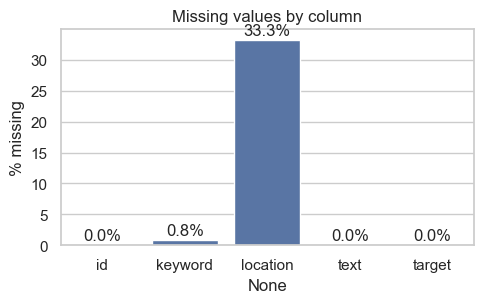

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\01_missing_values.png


In [4]:
print("Shape:", df.shape); print(df.dtypes); print(df.describe(include="all").T.to_string())
miss = df.isna().mean().mul(100).round(2)
print("\nMissing %:\n", miss)
FINDINGS["rows"], FINDINGS["cols"] = df.shape
FINDINGS["missing_pct"] = miss.to_dict()
plt.figure(figsize=(5, 3.2))
ax = sns.barplot(x=miss.index, y=miss.values, color=BLUE)
for i, v in enumerate(miss.values): ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
ax.set_ylabel("% missing"); ax.set_title("Missing values by column"); save("01_missing_values")

## 2. Target distribution

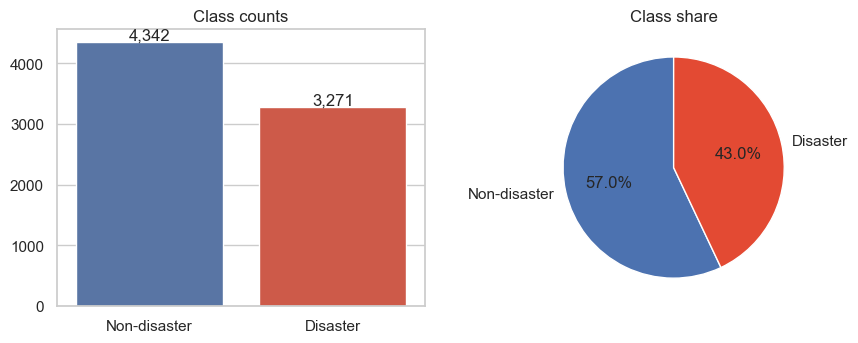

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\02_target_distribution.png
target
0    4342
1    3271
Name: count, dtype: int64 
Imbalance ratio: 1.33:1  (mild — no resampling required)


In [5]:
vc = df["target"].value_counts().sort_index()
FINDINGS["class_counts"] = {LAB[k]: int(v) for k, v in vc.items()}
FINDINGS["disaster_share"] = round(vc[1] / len(df), 4)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
sns.barplot(x=[LAB[i] for i in vc.index], y=vc.values, palette=[PAL[i] for i in vc.index], ax=ax[0])
for i, v in enumerate(vc.values): ax[0].text(i, v + 40, f"{v:,}", ha="center")
ax[0].set_title("Class counts")
ax[1].pie(vc.values, labels=[LAB[i] for i in vc.index], autopct="%1.1f%%", colors=[PAL[i] for i in vc.index], startangle=90)
ax[1].set_title("Class share"); save("02_target_distribution")
print(vc, f"\nImbalance ratio: {vc.max()/vc.min():.2f}:1  (mild — no resampling required)")

## 3. `keyword` column

Unique keywords: 221 | tweets per keyword (median): 35.0


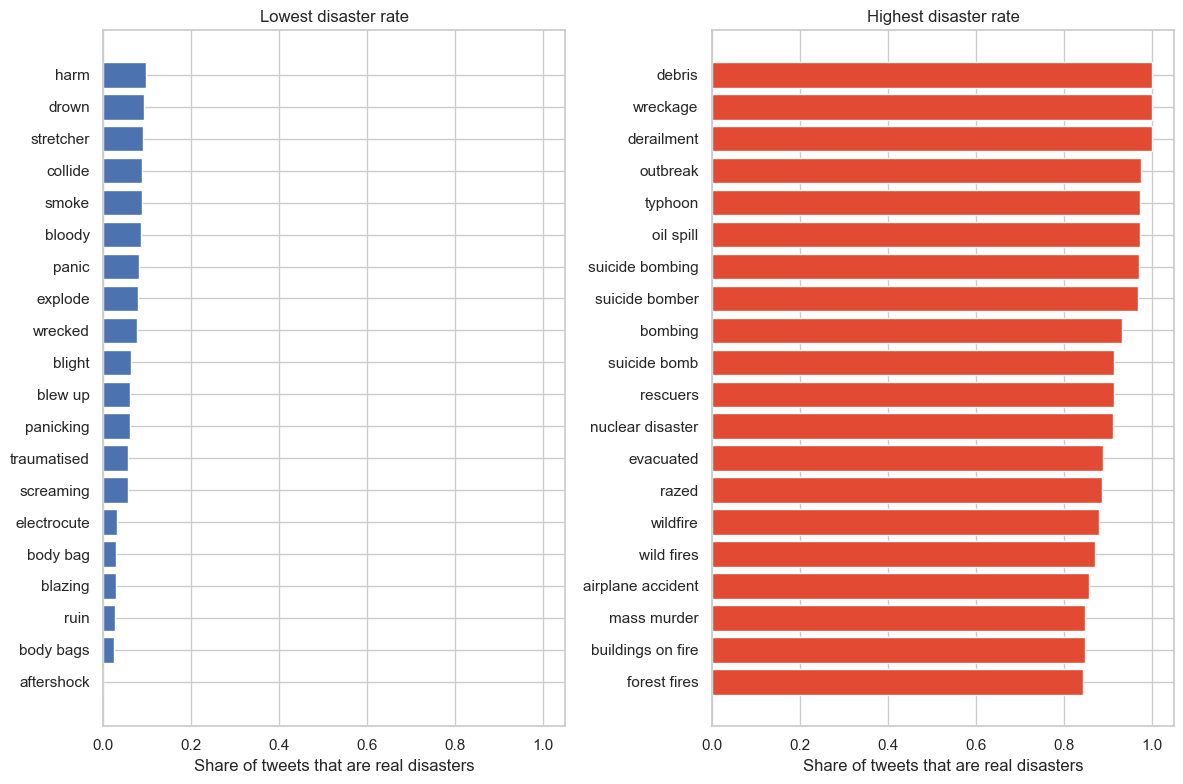

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\03_keyword_disaster_rate.png


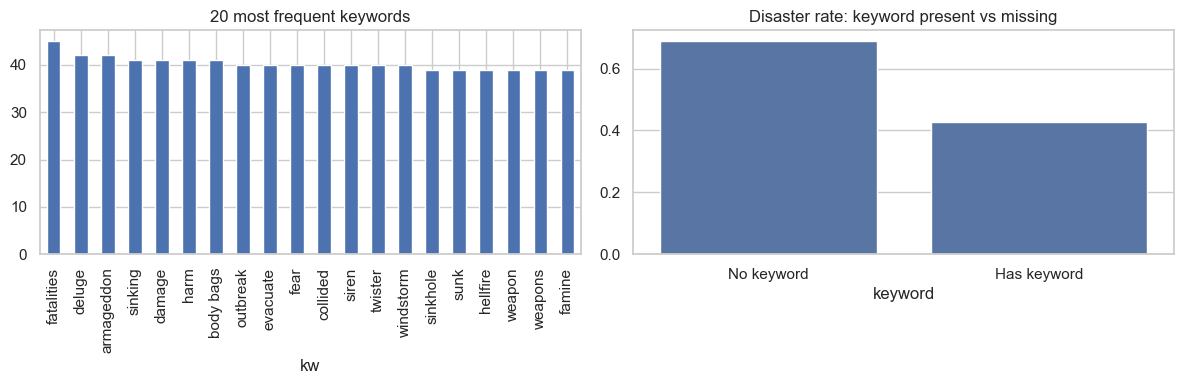

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\04_keyword_frequency.png
Chi² keyword↔target: chi2=2268.7, p=0.00e+00  -> keyword is strongly associated with the label


In [6]:
df["kw"] = df["keyword"].str.replace("%20", " ", regex=False)
FINDINGS["n_keywords"] = int(df["kw"].nunique())
kw = df.dropna(subset=["kw"]).groupby("kw")["target"].agg(rate="mean", n="count")
print("Unique keywords:", len(kw), "| tweets per keyword (median):", kw["n"].median())
fig, ax = plt.subplots(1, 2, figsize=(12, 8), sharex=True)
top = kw[kw.n >= 20].sort_values("rate")
for a, sel, title, col in [(ax[0], top.head(20), "Lowest disaster rate", BLUE), (ax[1], top.tail(20), "Highest disaster rate", RED)]:
    a.barh(sel.index, sel["rate"], color=col); a.set_title(title); a.set_xlabel("Share of tweets that are real disasters")
save("03_keyword_disaster_rate")
FINDINGS["keywords_highest_rate"] = top.tail(5).index.tolist()[::-1]
FINDINGS["keywords_lowest_rate"] = top.head(5).index.tolist()
FINDINGS["keyword_rate_range"] = [round(top.rate.min(), 3), round(top.rate.max(), 3)]

# keyword frequency + presence vs target
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
kw["n"].sort_values(ascending=False).head(20).plot.bar(ax=ax[0], color=BLUE); ax[0].set_title("20 most frequent keywords")
has = df.groupby(df["keyword"].notna())["target"].mean().rename({False: "No keyword", True: "Has keyword"})
sns.barplot(x=has.index, y=has.values, color=BLUE, ax=ax[1]); ax[1].set_title("Disaster rate: keyword present vs missing")
save("04_keyword_frequency")
chi = stats.chi2_contingency(pd.crosstab(df.dropna(subset=['kw']).kw, df.dropna(subset=['kw']).target))
print(f"Chi² keyword↔target: chi2={chi[0]:.1f}, p={chi[1]:.2e}  -> keyword is strongly associated with the label")
FINDINGS["keyword_chi2_p"] = float(chi[1])

## 4. `location` column (free text, very noisy)

Non-null: 5079 | unique: 3278
location
USA                105
New York            73
United States       50
London              46
Nigeria             32
Canada              30
UK                  27
Los Angeles, CA     26
India               24
Mumbai              22
Washington, DC      21
Kenya               20
California          20
Chicago, IL         19
Worldwide           19
Name: count, dtype: int64


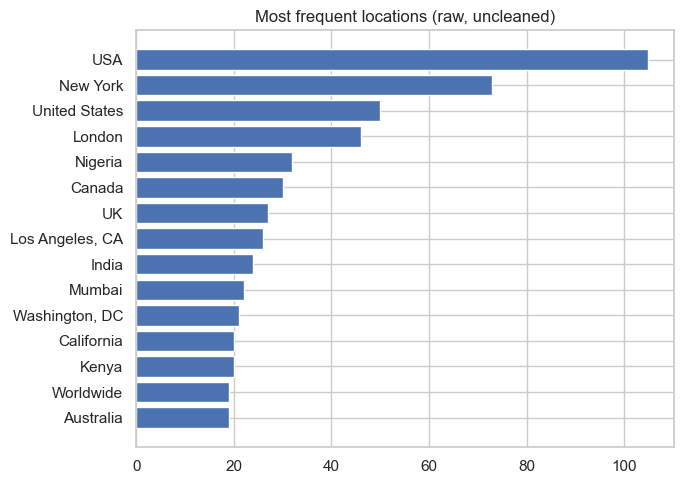

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\05_top_locations.png
-> free text ('Earth', 'worldwide', typos, emojis): low value without heavy cleaning; excluded from the model.


In [7]:
loc = df["location"].dropna().str.strip()
print("Non-null:", len(loc), "| unique:", loc.nunique())
print(loc.value_counts().head(15))
top_loc = df.dropna(subset=["location"]).groupby("location")["target"].agg(["count", "mean"]).query("count>=10").sort_values("count", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top_loc.index[::-1], top_loc["count"][::-1], color=BLUE); ax.set_title("Most frequent locations (raw, uncleaned)")
save("05_top_locations")
FINDINGS["location_unique"] = int(loc.nunique()); FINDINGS["location_missing_pct"] = round(df.location.isna().mean() * 100, 1)
print("-> free text ('Earth', 'worldwide', typos, emojis): low value without heavy cleaning; excluded from the model.")

## 5. Text length

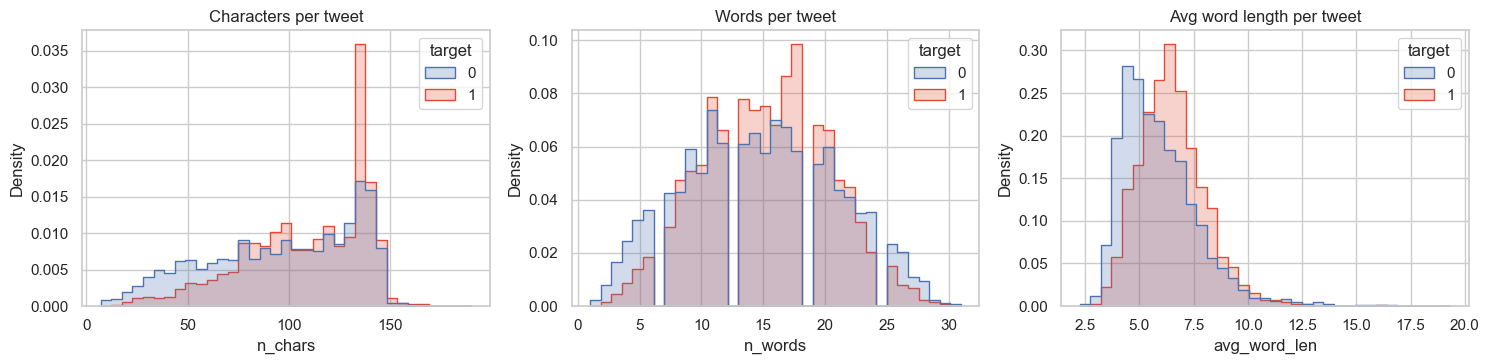

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\06_length_distributions.png
       n_chars        n_words        avg_word_len       
          mean median    mean median         mean median
target                                                  
0        96.30  101.0   14.70   15.0         5.91   5.57
1       108.83  115.0   15.17   15.0         6.51   6.38
Mann-Whitney n_chars: p=3.53e-46
Mann-Whitney n_words: p=2.65e-04
Mann-Whitney avg_word_len: p=3.29e-84


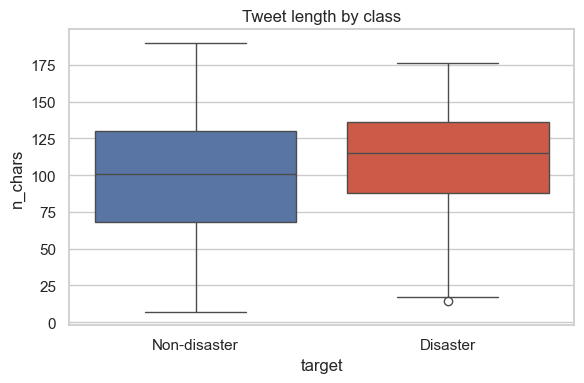

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\07_length_boxplot.png


In [8]:
df["n_chars"] = df.text.str.len()
df["n_words"] = df.text.str.split().str.len()
df["avg_word_len"] = df.text.str.split().map(lambda w: np.mean([len(x) for x in w]))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c, t in zip(ax, ["n_chars", "n_words", "avg_word_len"], ["Characters", "Words", "Avg word length"]):
    sns.histplot(data=df, x=c, hue="target", palette=PAL, bins=35, stat="density", common_norm=False, element="step", ax=a)
    a.set_title(f"{t} per tweet")
save("06_length_distributions")
summ = df.groupby("target")[["n_chars", "n_words", "avg_word_len"]].agg(["mean", "median"]).round(2)
print(summ)
for c in ["n_chars", "n_words", "avg_word_len"]:
    u = stats.mannwhitneyu(df.loc[df.target == 1, c], df.loc[df.target == 0, c])
    print(f"Mann-Whitney {c}: p={u.pvalue:.2e}")
FINDINGS["length_summary"] = {c: {LAB[t]: float(df[df.target == t][c].mean().round(2)) for t in (0, 1)} for c in ["n_chars", "n_words", "avg_word_len"]}
plt.figure(figsize=(6, 4)); sns.boxplot(data=df, x="target", y="n_chars", hue="target", palette=PAL, legend=False); plt.xticks([0, 1], [LAB[0], LAB[1]])
plt.title("Tweet length by class"); save("07_length_boxplot")

## 6. Twitter artifacts: hashtags, mentions, URLs, punctuation, case, encoding junk

target                       Non-disaster  Disaster
Contains URL                         41.4      66.4
Has hashtag                          20.4      26.3
Has @mention                         31.0      20.4
Has '!'                              12.0       6.0
Has '?'                              17.3       8.9
Contains digit                       51.0      73.9
Encoding junk / HTML entity          12.7      14.0
Retweet                               0.4       0.6


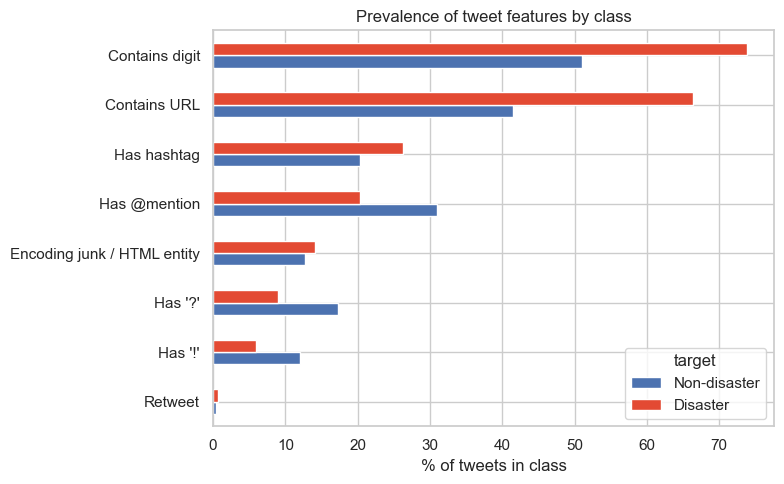

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\08_twitter_artifacts.png


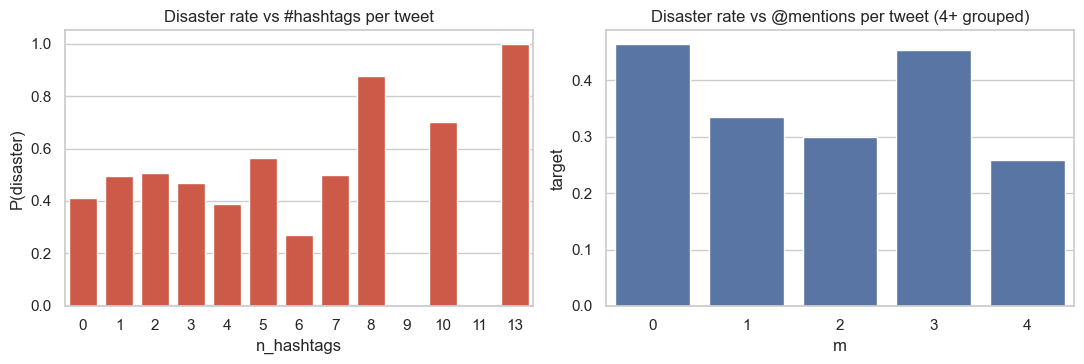

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\09_hashtag_mention_rate.png


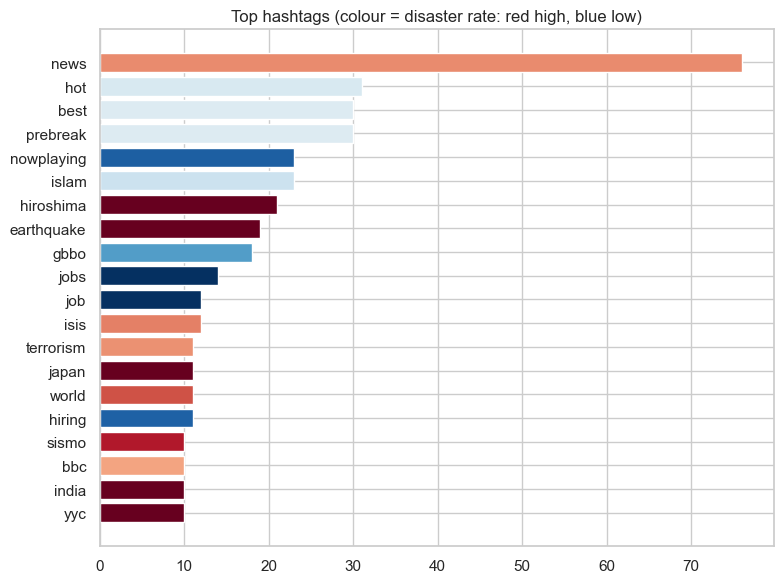

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\10_top_hashtags.png


In [9]:
t = df.text
df["n_hashtags"] = t.str.count(r"#\w+"); df["n_mentions"] = t.str.count(r"@\w+")
df["has_url"] = t.str.contains(r"https?://", regex=True).astype(int)
df["n_exclaim"] = t.str.count("!"); df["n_question"] = t.str.count(r"\?")
df["caps_ratio"] = t.map(lambda s: sum(c.isupper() for c in s) / max(len(s), 1))
df["has_digit"] = t.str.contains(r"\d").astype(int)
df["has_encoding_junk"] = t.str.contains(r"Û|å|ÃŸ|_x00|&amp;|&lt;|&gt;", regex=True).astype(int)
df["is_retweet"] = t.str.startswith("RT ").astype(int)

flag_cols = {"has_url": "Contains URL", "n_hashtags": "Has hashtag", "n_mentions": "Has @mention", "n_exclaim": "Has '!'",
             "n_question": "Has '?'", "has_digit": "Contains digit", "has_encoding_junk": "Encoding junk / HTML entity", "is_retweet": "Retweet"}
rates = {v: (df[k] > 0).groupby(df.target).mean() for k, v in flag_cols.items()}
rt = pd.DataFrame(rates).T.rename(columns=LAB) * 100
print(rt.round(1))
rt.sort_values("Disaster").plot.barh(color=[BLUE, RED], figsize=(8, 5)); plt.xlabel("% of tweets in class")
plt.title("Prevalence of tweet features by class"); save("08_twitter_artifacts")
FINDINGS["artifact_pct_by_class"] = rt.round(1).to_dict()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(data=df, x="n_hashtags", y="target", color=RED, ax=ax[0], errorbar=None); ax[0].set_title("Disaster rate vs #hashtags per tweet"); ax[0].set_ylabel("P(disaster)")
sns.barplot(data=df.assign(m=df.n_mentions.clip(upper=4)), x="m", y="target", color=BLUE, ax=ax[1], errorbar=None); ax[1].set_title("Disaster rate vs @mentions per tweet (4+ grouped)")
save("09_hashtag_mention_rate")

# top hashtags
tags = df.assign(tag=df.text.str.findall(r"#(\w+)")).explode("tag").dropna(subset=["tag"])
tags["tag"] = tags.tag.str.lower()
tt = tags.groupby("tag")["target"].agg(["count", "mean"]).query("count>=8").sort_values("count", ascending=False).head(20)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(tt.index[::-1], tt["count"][::-1], color=[plt.cm.RdBu_r(m) for m in tt["mean"][::-1]]); ax.set_title("Top hashtags (colour = disaster rate: red high, blue low)")
save("10_top_hashtags")

## 7. Vocabulary & n-grams

Vocabulary (after cleaning): 13,734 | tokens: 62,242 | hapax: 56.3% | stop-word share: 37.9%


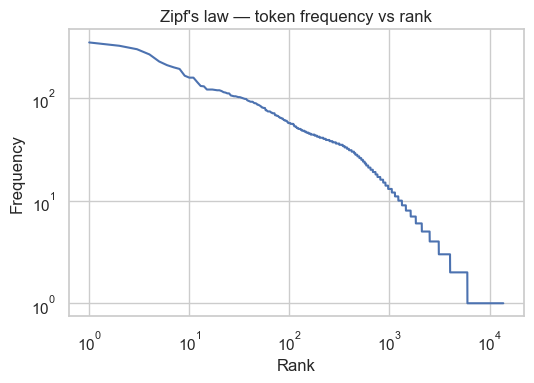

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\11_zipf.png


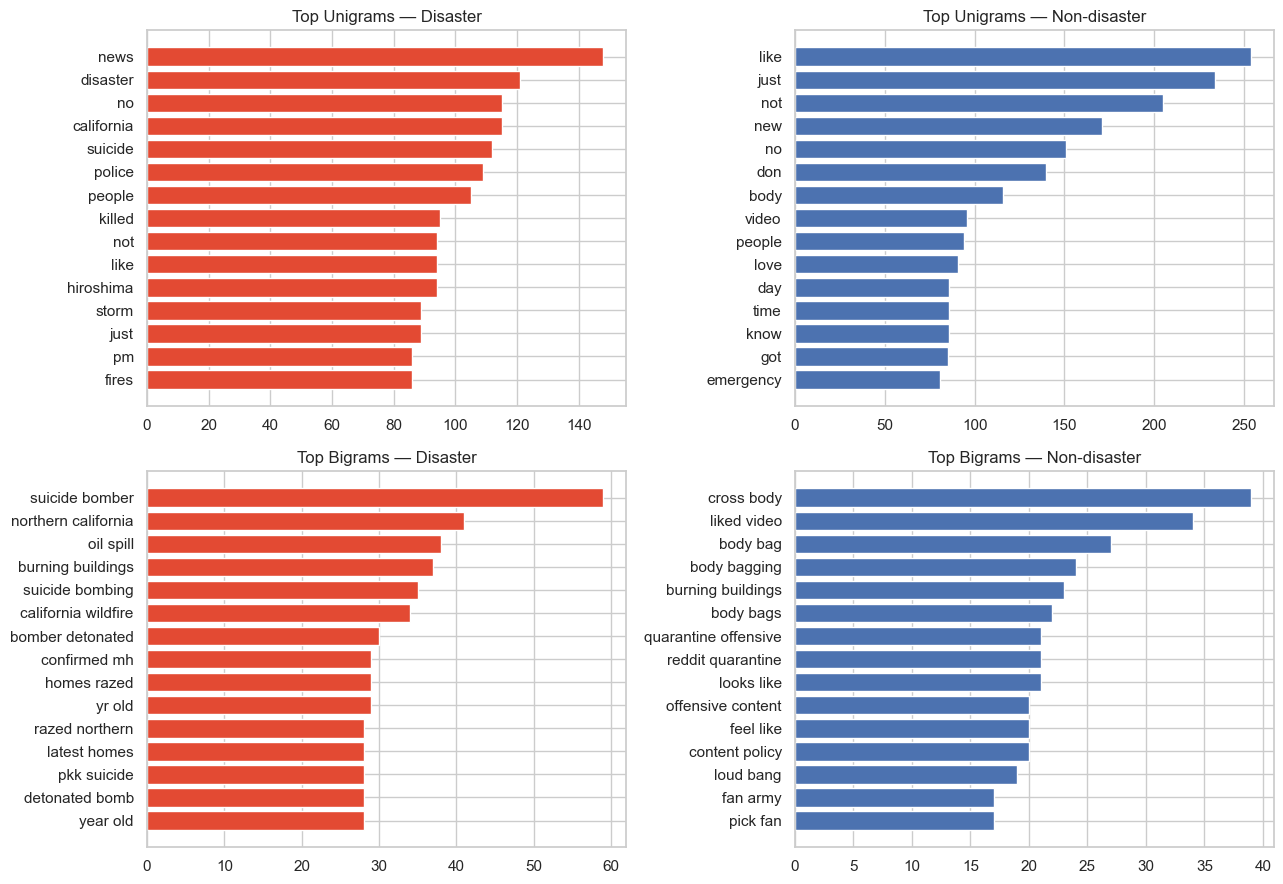

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\12_top_ngrams.png


In [10]:
df["clean"] = df.text.map(clean_text)
df["tokens"] = df.text.map(tokenize)
all_tok = [w for ts in df.tokens for w in ts]
cnt = Counter(all_tok)
raw_words = Counter(w for s in df.clean for w in s.split())
sw_ratio = sum(c for w, c in raw_words.items() if w in STOP_WORDS) / sum(raw_words.values())
FINDINGS.update(vocab_size=len(cnt), total_tokens=len(all_tok), hapax_pct=round(sum(1 for c in cnt.values() if c == 1) / len(cnt) * 100, 1), stopword_share=round(sw_ratio * 100, 1))
print(f"Vocabulary (after cleaning): {len(cnt):,} | tokens: {len(all_tok):,} | hapax: {FINDINGS['hapax_pct']}% | stop-word share: {FINDINGS['stopword_share']}%")

# Zipf plot
freqs = np.array(sorted(cnt.values(), reverse=True))
plt.figure(figsize=(5.5, 4)); plt.loglog(np.arange(1, len(freqs) + 1), freqs, color=BLUE)
plt.xlabel("Rank"); plt.ylabel("Frequency"); plt.title("Zipf's law — token frequency vs rank"); save("11_zipf")

def top_ngrams(texts, ngram, n=15):
    cv = CountVectorizer(ngram_range=(ngram, ngram), stop_words=list(STOP_WORDS), min_df=2)
    m = cv.fit_transform(texts); s = np.asarray(m.sum(0)).ravel()
    idx = s.argsort()[::-1][:n]; return [(cv.get_feature_names_out()[i], int(s[i])) for i in idx]

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for r, (ng, nm) in enumerate([(1, "Unigrams"), (2, "Bigrams")]):
    for c, lab in enumerate([1, 0]):
        tw = top_ngrams(df.loc[df.target == lab, "clean"], ng)
        ax[r, c].barh([w for w, _ in tw][::-1], [v for _, v in tw][::-1], color=PAL[lab]); ax[r, c].set_title(f"Top {nm} — {LAB[lab]}")
save("12_top_ngrams")
FINDINGS["top_bigrams_disaster"] = [w for w, _ in top_ngrams(df.loc[df.target == 1, "clean"], 2, 8)]
FINDINGS["top_bigrams_non"] = [w for w, _ in top_ngrams(df.loc[df.target == 0, "clean"], 2, 8)]

## 8. Word clouds

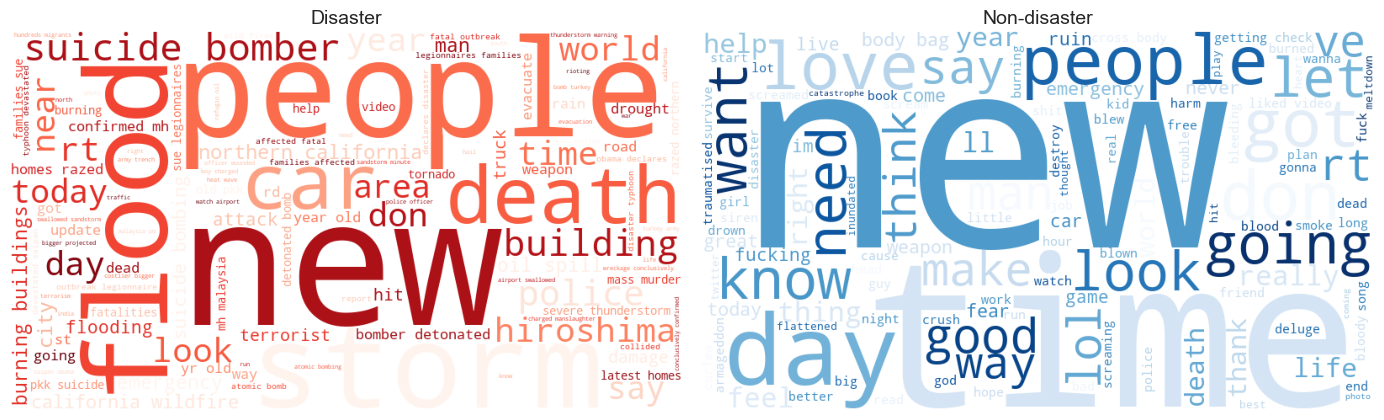

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\13_wordclouds.png


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, lab, cm in zip(ax, [1, 0], ["Reds", "Blues"]):
    txt = " ".join(df.loc[df.target == lab, "tokens"].map(" ".join))
    a.imshow(WordCloud(width=800, height=450, background_color="white", colormap=cm, max_words=120).generate(txt)); a.axis("off"); a.set_title(LAB[lab], fontsize=14)
save("13_wordclouds")

## 9. Most discriminative terms (log-odds ratio, smoothed)

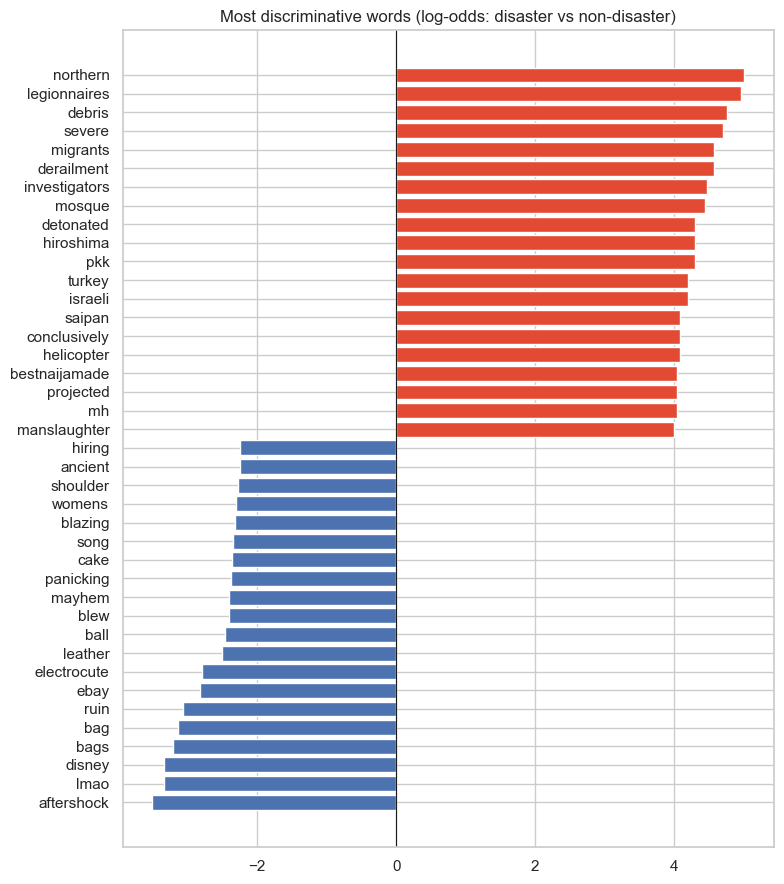

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\14_log_odds.png


In [12]:
def log_odds(min_count=15):
    c1 = Counter(w for ts in df[df.target == 1].tokens for w in ts); c0 = Counter(w for ts in df[df.target == 0].tokens for w in ts)
    n1, n0 = sum(c1.values()), sum(c0.values()); rows = []
    for w in set(c1) | set(c0):
        if c1[w] + c0[w] >= min_count:
            rows.append((w, np.log(((c1[w] + .5) / n1) / ((c0[w] + .5) / n0)), c1[w] + c0[w]))
    return pd.DataFrame(rows, columns=["word", "log_odds", "count"]).sort_values("log_odds")
lo = log_odds()
sel = pd.concat([lo.head(20), lo.tail(20)])
plt.figure(figsize=(8, 9)); plt.barh(sel.word, sel.log_odds, color=[BLUE] * 20 + [RED] * 20)
plt.axvline(0, color="k", lw=.8); plt.title("Most discriminative words (log-odds: disaster vs non-disaster)"); save("14_log_odds")
FINDINGS["most_disaster_words"] = lo.tail(10).word.tolist()[::-1]; FINDINGS["most_nondisaster_words"] = lo.head(10).word.tolist()

## 10. Duplicates, conflicting labels and noise

Rows in duplicate groups: 179 | texts with conflicting labels: 18
                                                                                                                                            text  target
4290  #Allah describes piling up #wealth thinking it would last #forever as the description of the people of #Hellfire in Surah Humaza. #Reflect       0
4299  #Allah describes piling up #wealth thinking it would last #forever as the description of the people of #Hellfire in Surah Humaza. #Reflect       0
4312  #Allah describes piling up #wealth thinking it would last #forever as the description of the people of #Hellfire in Surah Humaza. #Reflect       1
4244                       #foodscare #offers2go #NestleIndia slips into loss after #Magginoodle #ban unsafe and hazardous for #humanconsumption       0
4221                       #foodscare #offers2go #NestleIndia slips into loss after #Magginoodle #ban unsafe and hazardous for #humanconsumption       1
4239            

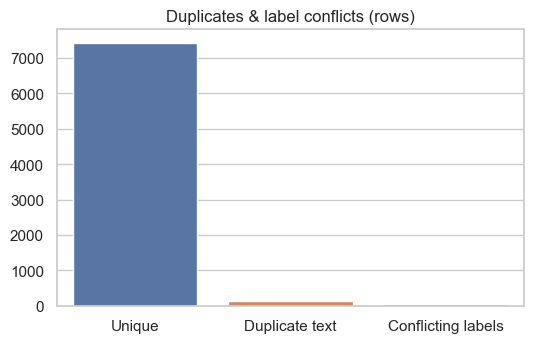

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\15_duplicates.png


In [13]:
dup = df.text.duplicated(keep=False)
g = df.groupby("text")["target"].nunique()
conflict_texts = g[g > 1]
FINDINGS.update(rows_in_duplicate_groups=int(dup.sum()), conflicting_label_texts=int(len(conflict_texts)),
                junk_pct=round(df.has_encoding_junk.mean() * 100, 1), url_pct=round(df.has_url.mean() * 100, 1))
print("Rows in duplicate groups:", dup.sum(), "| texts with conflicting labels:", len(conflict_texts))
print(df[df.text.isin(conflict_texts.index)].sort_values("text")[["text", "target"]].head(12).to_string())
print("\nNear-empty cleaned tweets (<3 tokens):", (df.tokens.str.len() < 3).sum())
fig, ax = plt.subplots(figsize=(5.5, 3.6))
cats = ["Unique", "Duplicate text", "Conflicting labels"]
vals = [(~dup).sum(), dup.sum() - df[df.text.isin(conflict_texts.index)].shape[0], df[df.text.isin(conflict_texts.index)].shape[0]]
sns.barplot(x=cats, y=vals, palette=[BLUE, "#dd8452", RED]); ax.set_title("Duplicates & label conflicts (rows)"); save("15_duplicates")

## 11. Meta-feature correlation with target

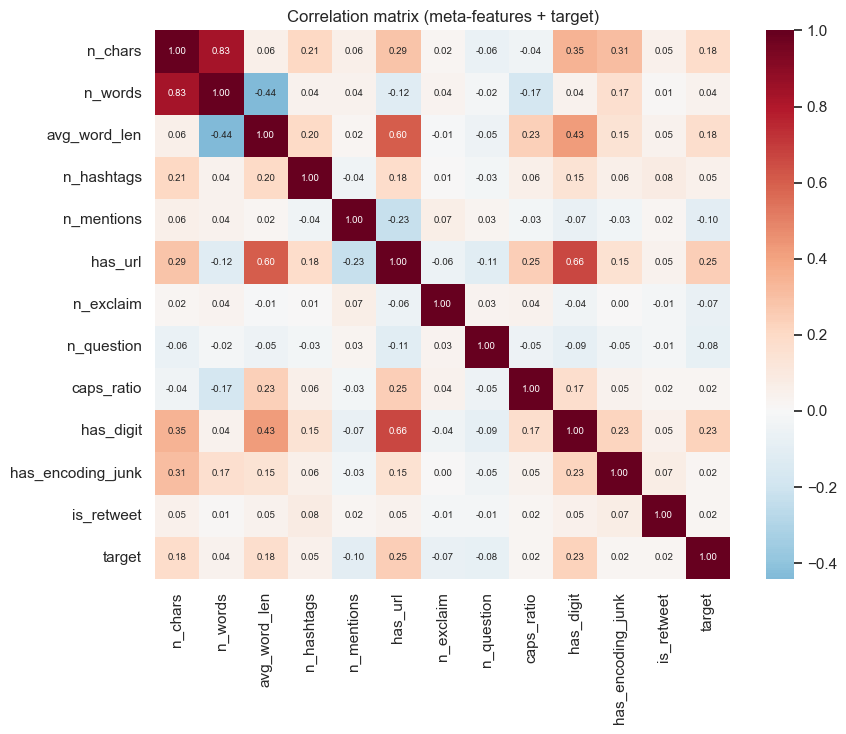

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\16_correlation_heatmap.png


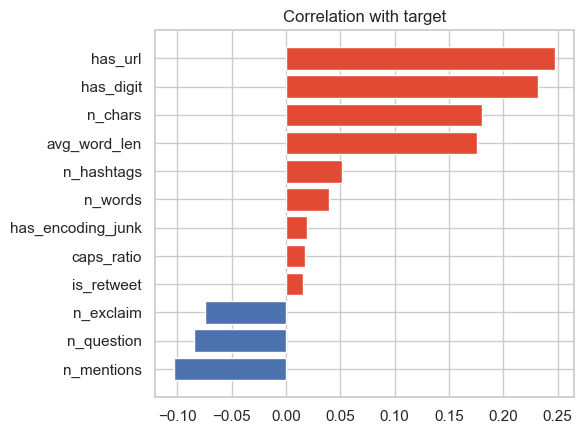

Chart saved: D:\nexthikes solutions internship\Project7\disaster_tweet_nlp\reports\eda\17_target_correlation.png
n_mentions          -0.103
n_question          -0.084
n_exclaim           -0.075
is_retweet           0.016
caps_ratio           0.018
has_encoding_junk    0.019
n_words              0.040
n_hashtags           0.052
avg_word_len         0.176
n_chars              0.181
has_digit            0.232
has_url              0.247
Name: target, dtype: float64


In [14]:
num = ["n_chars", "n_words", "avg_word_len", "n_hashtags", "n_mentions", "has_url", "n_exclaim", "n_question", "caps_ratio", "has_digit", "has_encoding_junk", "is_retweet"]
corr = df[num + ["target"]].corr()
plt.figure(figsize=(9, 7.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7}); plt.title("Correlation matrix (meta-features + target)")
save("16_correlation_heatmap")
tc = corr["target"].drop("target").sort_values()
plt.figure(figsize=(6, 4.5)); plt.barh(tc.index, tc.values, color=[RED if v > 0 else BLUE for v in tc.values]); plt.title("Correlation with target"); save("17_target_correlation")
FINDINGS["strongest_meta_corr"] = {k: round(float(v), 3) for k, v in tc.reindex(tc.abs().sort_values(ascending=False).index).head(4).items()}
print(tc.round(3))

## 12. Key findings & modelling implications

In [15]:
json.dump(FINDINGS, open(os.path.join(ROOT, "reports", "eda_findings.json"), "w"), indent=2, default=str)
print(json.dumps(FINDINGS, indent=2, default=str)[:3500])

{
  "location_non_text_cells": 29,
  "rows": 7613,
  "cols": 5,
  "missing_pct": {
    "id": 0.0,
    "keyword": 0.8,
    "location": 33.29,
    "text": 0.0,
    "target": 0.0
  },
  "class_counts": {
    "Non-disaster": 4342,
    "Disaster": 3271
  },
  "disaster_share": 0.4297,
  "n_keywords": 221,
  "keywords_highest_rate": [
    "debris",
    "wreckage",
    "derailment",
    "outbreak",
    "typhoon"
  ],
  "keywords_lowest_rate": [
    "aftershock",
    "body bags",
    "ruin",
    "blazing",
    "body bag"
  ],
  "keyword_rate_range": [
    0.0,
    1.0
  ],
  "keyword_chi2_p": 0.0,
  "location_unique": 3278,
  "location_missing_pct": 33.3,
  "length_summary": {
    "n_chars": {
      "Non-disaster": 96.3,
      "Disaster": 108.83
    },
    "n_words": {
      "Non-disaster": 14.7,
      "Disaster": 15.17
    },
    "avg_word_len": {
      "Non-disaster": 5.91,
      "Disaster": 6.51
    }
  },
  "artifact_pct_by_class": {
    "Non-disaster": {
      "Contains URL": 41.4,
      

## Key findings & modelling implications

| # | Finding | Implication |
|---|---|---|
| 1 | 7,613 tweets; **43.0% disaster** (3,271) vs 57.0% non-disaster (4,342); imbalance only 1.33:1 | No resampling needed; use stratified split and F1/precision/recall, not accuracy alone |
| 2 | `keyword`: 221 values, only 0.8% missing; extremely predictive (chi-square p ≈ 0). E.g. *wreckage, derailment, debris, outbreak, oil spill, typhoon* are ≥97% disaster, while *aftershock, body bags, ruin, blazing, electrocute* are ≤3% | Keep `keyword` as a model feature, but it is **not sufficient** alone: the same keyword is used literally and figuratively (59 of 216 keywords with n≥20 are ≤20% disaster) |
| 3 | `location`: 33% missing, 3,278 unique free-text values (plus 29 cells Excel auto-converted to dates/numbers) | Too noisy and not causally useful; excluded from the model |
| 4 | Disaster tweets are longer (mean 109 vs 96 chars) with longer words (6.5 vs 5.9 chars), both significant (Mann-Whitney p < 1e-45) | Length features carry modest signal (correlation ≈ 0.18) |
| 5 | **URLs: 66% of disaster vs 41% of non-disaster tweets** (corr 0.25); digits: 74% vs 51% (corr 0.23); @mentions, "?" and "!" are more common in non-disaster (casual conversation) | News-style tweets (link + numbers) vs chatty tweets. `has_url` is in the model; **digit presence is not yet** and is a candidate feature |
| 6 | Vocabulary after cleaning: 13,734 types, 62k tokens, 56% appear only once; stop-words ≈ 38% of raw tokens | Very sparse: use min_df / TF-IDF with sublinear tf and regularisation (the model overfits otherwise) |
| 7 | Top disaster bigrams: *suicide bomber, northern california, oil spill, california wildfire, homes razed*. Top non-disaster bigrams: *cross body, liked video, body bag, reddit quarantine* | Bigrams add signal and disambiguate (e.g. "body bag" vs "suicide bomber"), supporting the 1–2 gram TF-IDF choice |
| 8 | 179 rows sit in duplicate-text groups; **18 texts have conflicting labels** (e.g. identical tweet labelled 0 and 1); ~12–14% of tweets contain encoding junk / HTML entities | Labels are noisy, which caps achievable accuracy; de-duplicate before splitting to avoid leakage; clean HTML entities |
